In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

lre = LinearRegression()

Rcross = cross_val_score(
    lre,
    data[['horsepower']],
    Y,
    cv=4
)

print("Cross-validation scores:", Rcross)
print("Average score:", Rcross.mean())

Cross-validation scores: [0.77344651 0.53291315 0.72007907 0.04475435]
Average score: 0.5177982696090335


In [13]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Створюємо модель
pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# Визначаємо параметри для пошуку
parameters = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}

# Запускаємо GridSearch
grid = GridSearchCV(
    pipeline,
    parameters,
    cv=4
)

# Навчаємо модель
grid.fit(x_train, y_train)

# Виводимо результати
print("Best alpha:", grid.best_params_)
print("Best cross-validation score:", grid.best_score_)
print("Test score:", grid.score(x_test, y_test))

Best alpha: {'ridge__alpha': 100}
Best cross-validation score: 0.7552604201316846
Test score: 0.8255399217779822


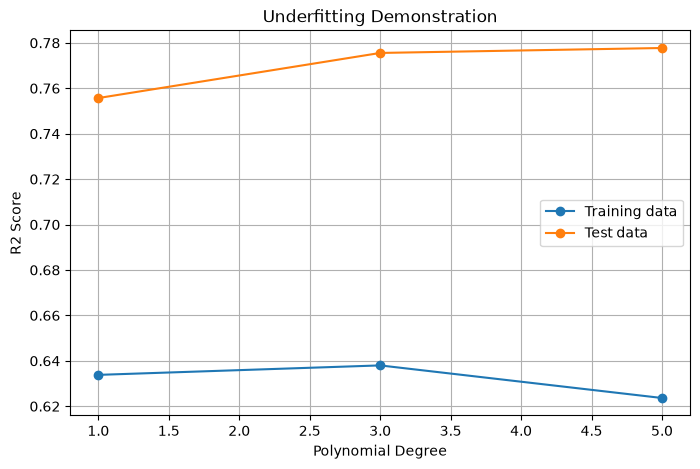

In [12]:
train_scores = []
test_scores = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(x_train[['horsepower']], y_train)

    train_scores.append(
        model.score(x_train[['horsepower']], y_train)
    )

    test_scores.append(
        model.score(x_test[['horsepower']], y_test)
    )

plt.figure(figsize=(8, 5))

plt.plot(degrees, train_scores, marker='o', label='Training data')
plt.plot(degrees, test_scores, marker='o', label='Test data')

plt.xlabel('Polynomial Degree')
plt.ylabel('R2 Score')
plt.title('Underfitting Demonstration')
plt.legend()
plt.grid()
plt.show()

In [10]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

degrees = [1, 3, 5]

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(x_train[['horsepower']], y_train)

    train_score = model.score(x_train[['horsepower']], y_train)
    test_score = model.score(x_test[['horsepower']], y_test)

    print("Degree:", degree)
    print("Training R2:", train_score)
    print("Test R2:", test_score)
    print("----------------------")

Degree: 1
Training R2: 0.6338173918743926
Test R2: 0.755704393472654
----------------------
Degree: 3
Training R2: 0.6379834565137008
Test R2: 0.775560648807559
----------------------
Degree: 5
Training R2: 0.6236347243171749
Test R2: 0.7777405643220116
----------------------


In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Використовуємо лише 15 навчальних прикладів
x_small = x_train.iloc[:15]
y_small = y_train.iloc[:15]

# Створюємо складну поліноміальну модель
pr = PolynomialFeatures(degree=3)

x_train_pr = pr.fit_transform(x_small)
x_test_pr = pr.transform(x_test)

# Навчаємо модель
overfit_model = LinearRegression()
overfit_model.fit(x_train_pr, y_small)

# Оцінюємо результати
print("Training R2:", overfit_model.score(x_train_pr, y_small))
print("Test R2:", overfit_model.score(x_test_pr, y_test))

Training R2: 0.9944097146778218
Test R2: 0.44754581788972814


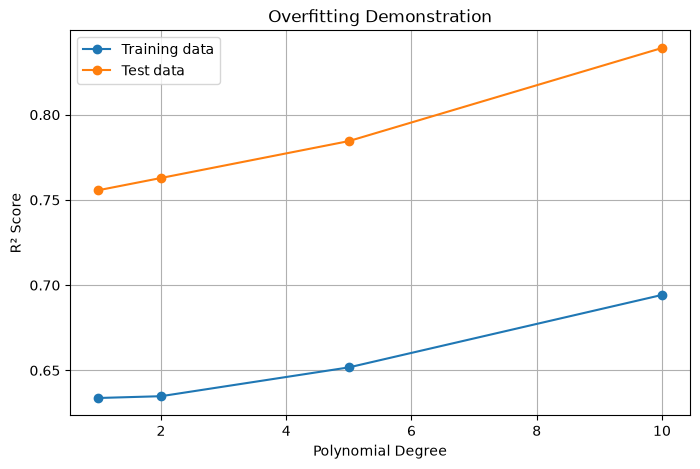

In [8]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

degrees = [1, 2, 5, 10]

train_scores = []
test_scores = []

for degree in degrees:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(x_train[['horsepower']], y_train)

    train_scores.append(
        model.score(x_train[['horsepower']], y_train)
    )

    test_scores.append(
        model.score(x_test[['horsepower']], y_test)
    )

plt.figure(figsize=(8, 5))

plt.plot(degrees, train_scores, marker='o', label='Training data')
plt.plot(degrees, test_scores, marker='o', label='Test data')

plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score')
plt.title('Overfitting Demonstration')
plt.legend()
plt.grid()
plt.show()

In [15]:
from sklearn.linear_model import LinearRegression

# Створюємо модель
lm = LinearRegression()

# Навчаєм модель
lm.fit(x_train, y_train)

# Робимо прогноз
yhat = lm.predict(x_test)

# Оцінюємо якість модели
print("Точність на навчальних даних:", lm.score(x_train, y_train))
print("Точність на тестових даних:", lm.score(x_test, y_test))

Точність на навчальних даних: 0.8080695904830413
Точність на тестових даних: 0.8083748680801492


In [6]:
from sklearn.model_selection import train_test_split

X = data[[
    "horsepower",
    "curb-weight",
    "engine-size",
    "highway-mpg"
]]

Y = data["price"]

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1
)

print("Навчальні рядки:", len(x_train))
print("Тестові рядки:", len(x_test))

Навчальні рядки: 159
Тестові рядки: 40


In [5]:

data = df[[
    "horsepower",
    "curb-weight",
    "engine-size",
    "highway-mpg",
    "price"
]].copy()


for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")


data = data.dropna()

print("Розмір набору даних:", data.shape)
print(data.head())

Розмір набору даних: (199, 5)
   horsepower  curb-weight  engine-size  highway-mpg    price
0       111.0         2548          130           27  13495.0
1       111.0         2548          130           27  16500.0
2       154.0         2823          152           26  16500.0
3       102.0         2337          109           30  13950.0
4       115.0         2824          136           22  17450.0


In [4]:
import pandas as pd
import numpy as np

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

columns = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-type", "num-of-cylinders", "engine-size",
    "fuel-system", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
]

df = pd.read_csv(url, names=columns, na_values="?")

print(df.head())

   symboling  normalized-losses         make fuel-type aspiration  \
0          3                NaN  alfa-romero       gas        std   
1          3                NaN  alfa-romero       gas        std   
2          1                NaN  alfa-romero       gas        std   
3          2              164.0         audi       gas        std   
4          2              164.0         audi       gas        std   

  num-of-doors   body-style drive-wheels engine-location  wheel-base  ...  \
0          two  convertible          rwd           front        88.6  ...   
1          two  convertible          rwd           front        88.6  ...   
2          two    hatchback          rwd           front        94.5  ...   
3         four        sedan          fwd           front        99.8  ...   
4         four        sedan          4wd           front        99.4  ...   

   engine-size  fuel-system  bore  stroke compression-ratio horsepower  \
0          130         mpfi  3.47    2.68       

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
print("Hello, Data Analytics!")

Hello, Data Analytics!
